In [4]:
import numpy as np
import pandas as pd

from pathlib import Path
from IPython.display import display

print("Libraries imported successfully.")

Libraries imported successfully.


Load datasets and recommendations

In [5]:
PROJECT_ROOT = Path.cwd().parent

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
REPORT_DIR = PROJECT_ROOT / "runs" / "reports"

candidate_df = pd.read_csv(
    REPORT_DIR / "faiss_candidate_recommendations.csv"
)

ranked_df = pd.read_csv(
    REPORT_DIR / "final_ranked_recommendations.csv"
)

test_df = pd.read_csv(
    PROCESSED_DIR / "test.csv"
)

print("FAISS candidates:", candidate_df.shape)
print("Final ranked recommendations:", ranked_df.shape)
print("Test data:", test_df.shape)

display(ranked_df.head())

FAISS candidates: (61000, 6)
Final ranked recommendations: (6100, 34)
Test data: (10599, 6)


,user_idx,rank,movie_idx,similarity_score,title,genres,label,genres_list,user_avg_rating,user_rating_count,...,genre_IMAX,genre_Musical,genre_Mystery,genre_Romance,genre_Sci-Fi,genre_Thriller,genre_War,genre_Western,ranking_score,final_rank
0,0,32,2460,-0.221182,Scream 3 (2000),Comedy|Horror|Mystery|Thriller,1,"['Comedy', 'Horror', 'Mystery', 'Thriller']",4.367568,5.225747,...,0,0,1,0,0,1,0,0,0.613313,1
1,0,56,1850,-0.237648,"Texas Chainsaw Massacre, The (1974)",Horror,1,['Horror'],4.367568,5.225747,...,0,0,0,0,0,0,0,0,0.485186,2
2,0,2,1288,-0.182374,Scream 2 (1997),Comedy|Horror|Mystery|Thriller,0,"['Comedy', 'Horror', 'Mystery', 'Thriller']",4.367568,5.225747,...,0,0,1,0,0,1,0,0,0.470660,3
3,0,6,3661,-0.200133,Dragonslayer (1981),Action|Adventure|Fantasy,0,"['Action', 'Adventure', 'Fantasy']",4.367568,5.225747,...,0,0,0,0,0,0,0,0,0.356449,4
4,0,57,3572,-0.237681,Shallow Hal (2001),Comedy|Fantasy|Romance,0,"['Comedy', 'Fantasy', 'Romance']",4.367568,5.225747,...,0,0,0,1,0,0,0,0,0.293128,5


Prepare relevant test movies

In [6]:
RELEVANCE_THRESHOLD = 4.0
K = 10

test_positive_df = test_df[
    test_df["rating"] >= RELEVANCE_THRESHOLD
].copy()

relevant_movies = (
    test_positive_df
    .groupby("user_idx")["movie_idx"]
    .apply(set)
    .to_dict()
)

print("Positive test interactions:", len(test_positive_df))
print("Users with relevant test movies:", len(relevant_movies))

Positive test interactions: 5058
Users with relevant test movies: 574


Define evaluation metrics

In [7]:
def recall_at_k(recommended, relevant, k=10):
    if not relevant:
        return 0.0

    hits = len(set(recommended[:k]) & relevant)
    return hits / len(relevant)


def precision_at_k(recommended, relevant, k=10):
    hits = len(set(recommended[:k]) & relevant)
    return hits / k


def ndcg_at_k(recommended, relevant, k=10):
    dcg = sum(
        1 / np.log2(rank + 1)
        for rank, movie_idx in enumerate(recommended[:k], start=1)
        if movie_idx in relevant
    )

    ideal_hits = min(len(relevant), k)

    idcg = sum(
        1 / np.log2(rank + 1)
        for rank in range(1, ideal_hits + 1)
    )

    return dcg / idcg if idcg else 0.0

Calculate FAISS Candidate Recall@100

In [8]:
candidate_lookup = (
    candidate_df.groupby("user_idx")["movie_idx"]
    .apply(set)
    .to_dict()
)

candidate_recalls = []

for user_idx, relevant in relevant_movies.items():

    candidates = candidate_lookup.get(user_idx, set())

    recall = (
        len(candidates & relevant) / len(relevant)
        if relevant else 0.0
    )

    candidate_recalls.append(recall)

candidate_recall_100 = np.mean(candidate_recalls)

print("FAISS Candidate Generation Results")
print("-----------------------------------")
print(f"Candidate Recall@100: {candidate_recall_100:.4f}")
print("Evaluated users:", len(candidate_recalls))

FAISS Candidate Generation Results
-----------------------------------
Candidate Recall@100: 0.1404
Evaluated users: 574


Calculate final ranking metrics

In [9]:
ranked_lookup = (
    ranked_df.sort_values(["user_idx", "final_rank"])
    .groupby("user_idx")["movie_idx"]
    .apply(list)
    .to_dict()
)

recall_scores = []
precision_scores = []
ndcg_scores = []

for user_idx, relevant in relevant_movies.items():

    recommendations = ranked_lookup.get(user_idx, [])

    recall_scores.append(
        recall_at_k(recommendations, relevant, K)
    )

    precision_scores.append(
        precision_at_k(recommendations, relevant, K)
    )

    ndcg_scores.append(
        ndcg_at_k(recommendations, relevant, K)
    )

final_recall = np.mean(recall_scores)
final_precision = np.mean(precision_scores)
final_ndcg = np.mean(ndcg_scores)

print("Final Two-Stage Recommendation Results")
print("--------------------------------------")
print(f"Recall@10:    {final_recall:.4f}")
print(f"Precision@10: {final_precision:.4f}")
print(f"NDCG@10:      {final_ndcg:.4f}")
print("Evaluated users:", len(recall_scores))

Final Two-Stage Recommendation Results
--------------------------------------
Recall@10:    0.0422
Precision@10: 0.0190
NDCG@10:      0.0282
Evaluated users: 574


Compare all models

In [10]:
comparison_df = pd.DataFrame({
    "Model": [
        "Popularity-Based",
        "User-Based Collaborative Filtering",
        "Two-Tower Retrieval",
        "Two-Stage FAISS + Random Forest"
    ],
    "Recall@10": [
        0.0426,
        0.0666,
        0.0152,
        final_recall
    ],
    "NDCG@10": [
        0.0438,
        0.0637,
        0.0134,
        final_ndcg
    ]
})

display(
    comparison_df.sort_values(
        "Recall@10",
        ascending=False
    )
)

,Model,Recall@10,NDCG@10
1,User-Based Collaborative Filtering,0.066600,0.063700
0,Popularity-Based,0.042600,0.043800
3,Two-Stage FAISS + Random Forest,0.042155,0.028226
2,Two-Tower Retrieval,0.015200,0.013400


Save final evaluation results

In [11]:
final_metrics = pd.DataFrame({
    "Metric": [
        "Candidate Recall@100",
        "Final Recall@10",
        "Final Precision@10",
        "Final NDCG@10"
    ],
    "Value": [
        candidate_recall_100,
        final_recall,
        final_precision,
        final_ndcg
    ]
})

display(final_metrics)

final_metrics.to_csv(
    REPORT_DIR / "final_evaluation_metrics.csv",
    index=False
)

comparison_df.to_csv(
    REPORT_DIR / "model_comparison.csv",
    index=False
)

print("Final evaluation reports saved successfully.")

,Metric,Value
0,Candidate Recall@100,0.140402
1,Final Recall@10,0.042155
2,Final Precision@10,0.018990
3,Final NDCG@10,0.028226


Final evaluation reports saved successfully.


Visualize model comparison

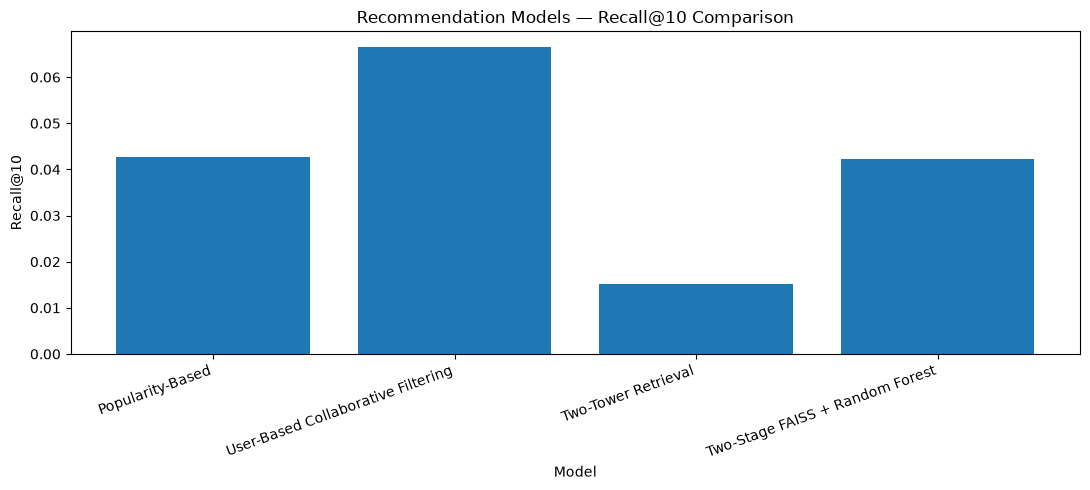

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 5))

plt.bar(
    comparison_df["Model"],
    comparison_df["Recall@10"]
)

plt.title("Recommendation Models — Recall@10 Comparison")
plt.xlabel("Model")
plt.ylabel("Recall@10")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

Inspect final recommendations for a user

In [13]:
sample_user_idx = 0

sample_results = (
    ranked_df[
        ranked_df["user_idx"] == sample_user_idx
    ]
    .sort_values("final_rank")
)

display(
    sample_results[
        [
            "final_rank",
            "title",
            "genres",
            "similarity_score",
            "ranking_score"
        ]
    ]
)

,final_rank,title,genres,similarity_score,ranking_score
0,1,Scream 3 (2000),Comedy|Horror|Mystery|Thriller,-0.221182,0.613313
1,2,"Texas Chainsaw Massacre, The (1974)",Horror,-0.237648,0.485186
2,3,Scream 2 (1997),Comedy|Horror|Mystery|Thriller,-0.182374,0.470660
3,4,Dragonslayer (1981),Action|Adventure|Fantasy,-0.200133,0.356449
4,5,Shallow Hal (2001),Comedy|Fantasy|Romance,-0.237681,0.293128
5,6,Creepshow (1982),Horror,-0.249053,0.281191
6,7,"Dark Crystal, The (1982)",Adventure|Fantasy,-0.238377,0.269246
7,8,"Addams Family, The (1991)",Children|Comedy|Fantasy,-0.226755,0.258124
8,9,Keeping the Faith (2000),Comedy|Drama|Romance,-0.213885,0.235307
9,10,Escape from L.A. (1996),Action|Adventure|Sci-Fi|Thriller,-0.215423,0.225672
